# 115 · Project 8: a dual-system TableTop agent: a language-model planner (System 2) + a language-conditioned policy (System 1)

In [1]:
import os, re, json, time, numpy as np, torch, mujoco, matplotlib.pyplot as plt
from PIL import Image
from transformers import AutoTokenizer, AutoModelForCausalLM
from vlacourse import TableTop, show_video, wilson
from vlacourse.torch_data import TableTopDataset
from vlacourse.lang import TextEmbedder, LangDataset, LangChunkRegression, LangChunkPolicy

from vlacourse import scene_dataset
SCENE = "sort"                    # TableTop scene tier (see vlacourse.SCENES)
DATA = scene_dataset(SCENE)          # 500 demos, recorded once with all CPU cores if missing
device = "cuda" if torch.cuda.is_available() else "cpu"
H = 16
LONG_TASKS = [   # "sort" scene: two cubes + one tray; each long instruction = two sub-tasks for System 1
    ("put the {a} cube in the {t} tray and then put the {b} cube in the {t} tray", lambda a, b, t: [("place", a, t), ("place", b, t)]),
    ("first move the {b} cube into the {t} tray, after that the {a} cube", lambda a, b, t: [("place", b, t), ("place", a, t)]),
]
# Few-shot examples use colours that never appear in our scene (purple/orange/white): a planner that just copies
# the example is caught immediately instead of looking half-right.
SYS2_PROMPT = """Split the robot instruction into simple steps, in the order they must happen. Use only these step forms:
"put the <colour> cube in the <colour> tray" or "pick up the <colour> cube". One step per line, numbered, nothing else.

Instruction: put the purple cube in the white tray and then put the orange cube in the white tray
1. put the purple cube in the white tray
2. put the orange cube in the white tray

Instruction: first move the orange cube into the white tray, after that the purple cube
1. put the orange cube in the white tray
2. put the purple cube in the white tray

Instruction: {instruction}
"""

def subtask_text(kind, o, t):
    return {"pick": f"pick up the {o} cube", "place": f"put the {o} cube in the {t} tray", "stack": f"stack the {o} cube on the {t} cube"}[kind]

def parse_steps(text):
    steps = []
    for line in text.splitlines():
        line = re.sub(r"^\s*\d+[.)]\s*", "", line).strip().lower()
        m = re.match(r"(put|place|move|stack|pick up) the (\w+) cube ?(?:(?:in|into|to) the (\w+) tray|on the (\w+) cube)?", line)
        if m:
            kind = {"put": "place", "place": "place", "move": "place", "stack": "stack", "pick up": "pick"}[m.group(1)]
            if kind != "pick" and not (m.group(3) or m.group(4)):
                continue                      # malformed step (e.g. "the tray" without a colour): the plan is wrong
            steps.append(dict(type=kind, obj=m.group(2), target=m.group(3) or m.group(4), instruction=subtask_text(kind, m.group(2), m.group(3) or m.group(4))))
    return steps

class System2:
    """A small instruction-tuned LLM as the slow planner. (SmolVLM-256M was tried first: it copied the few-shot
    example verbatim for every instruction. Planning needs more language capacity than a 256M model has.
    Production systems use a VLM here so the planner also sees the scene.)"""
    def __init__(self, mid="HuggingFaceTB/SmolLM2-1.7B-Instruct"):
        self.tok = AutoTokenizer.from_pretrained(mid)
        self.lm = AutoModelForCausalLM.from_pretrained(mid, dtype=torch.bfloat16 if device == "cuda" else torch.float32).to(device).eval()
    @torch.no_grad()
    def plan(self, instruction):
        msgs = [{"role": "user", "content": SYS2_PROMPT.format(instruction=instruction)}]
        x = self.tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt", return_dict=True).to(device)
        out = self.lm.generate(**x, max_new_tokens=60, do_sample=False)
        return self.tok.decode(out[0, x["input_ids"].shape[1]:], skip_special_tokens=True)

def run_episode(env, sys1, steps, seed, budget=200, frames=None):
    env.reset(seed=seed); home = env.target_pos.copy()
    done_steps, t = 0, 0
    for st in steps:
        known = env.cube_colors + env.tray_colors
        if st["obj"] not in env.cube_colors or (st["type"] != "pick" and st["target"] not in known):
            continue                          # the plan refers to an object that isn't on the table: that step fails
        env.task = st
        sys1.reset(); obs = env.observe(); k = 0
        while not env.success() and k < budget // len(steps):
            obs, *_ = env.step(sys1.act(obs)); k += 1; t += 1
            if frames is not None:
                frames.append(obs["images"]["front"])
        for _ in range(5):                                               # release and lift clear
            obs, *_ = env.step(np.r_[0, 0, 0.02, 0, 0, 0, 0.0])
        for _ in range(15):                                              # retract home: each sub-task starts where demos did
            obs, *_ = env.step(np.r_[np.clip(home - env.target_pos, -0.05, 0.05), 0, 0, 0, 0.0])
        done_steps += int(env.success()) if st["type"] == "pick" else int(sub_success(env, st))
    return done_steps

def sub_success(env, st):
    saved = env.task; env.task = st; ok = env.success(); env.task = saved
    return ok

~/anaconda3/envs/vla/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
emb = TextEmbedder(device=device)
base = TableTopDataset(DATA, episodes=range(450), horizon=H)
ds = LangDataset(base, emb)
net = LangChunkRegression(lang_dim=emb.dim, horizon=H, fusion="film")
from vlacourse import need; need("../S09_Vision_Language_Foundations/checkpoints/lang_film.pt", "S09 notebook 90")
net.load_state_dict(torch.load("../S09_Vision_Language_Foundations/checkpoints/lang_film.pt", map_location=device)); net.to(device).eval()
env = TableTop(scene=SCENE, cameras=("front", "wrist"), image_size=(128, 128), seed=0)
sys1 = LangChunkPolicy(net, ds, env, emb, device=device, ensemble=True)
sys2 = System2()

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 71089.90it/s]

Loading weights:   0%|          | 0/218 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 218/218 [00:00<00:00, 18208.87it/s]

In [3]:
colors_c, tray = env.cube_colors, env.tray_colors[0]
rng = np.random.default_rng(0)
episodes = []
for i in range(20):
    a, b = rng.permutation(colors_c)
    tpl, truth = LONG_TASKS[i % 2]
    episodes.append((tpl.format(a=a, b=b, t=tray), [dict(type=k, obj=o, target=t2, instruction=subtask_text(k, o, t2)) for k, o, t2 in truth(a, b, tray)]))
t0 = time.time(); plans = []
for instr, truth in episodes:
    raw = sys2.plan(instr); steps = parse_steps(raw)
    plans.append(steps); ok = [s["instruction"] for s in steps] == [s["instruction"] for s in truth]
    print(f"{'OK ' if ok else 'BAD'} {instr}\n     -> {[s['instruction'] for s in steps]}")
plan_acc = np.mean([[s["instruction"] for s in p] == [s["instruction"] for s in tr] for p, (_, tr) in zip(plans, episodes)])
print(f"System 2 decomposition accuracy: {plan_acc:.2f}  ({(time.time() - t0) / len(episodes):.1f}s per plan: it runs once per task, not every control step)")

OK  put the red cube in the blue tray and then put the green cube in the blue tray
     -> ['put the red cube in the blue tray', 'put the green cube in the blue tray']


OK  first move the green cube into the blue tray, after that the red cube
     -> ['put the green cube in the blue tray', 'put the red cube in the blue tray']


OK  put the red cube in the blue tray and then put the green cube in the blue tray
     -> ['put the red cube in the blue tray', 'put the green cube in the blue tray']


OK  first move the red cube into the blue tray, after that the green cube
     -> ['put the red cube in the blue tray', 'put the green cube in the blue tray']


OK  put the green cube in the blue tray and then put the red cube in the blue tray
     -> ['put the green cube in the blue tray', 'put the red cube in the blue tray']


OK  first move the green cube into the blue tray, after that the red cube
     -> ['put the green cube in the blue tray', 'put the red cube in the blue tray']


... (10 outputs left out)

OK  put the red cube in the blue tray and then put the green cube in the blue tray
     -> ['put the red cube in the blue tray', 'put the green cube in the blue tray']


OK  first move the green cube into the blue tray, after that the red cube
     -> ['put the green cube in the blue tray', 'put the red cube in the blue tray']


OK  put the red cube in the blue tray and then put the green cube in the blue tray
     -> ['put the red cube in the blue tray', 'put the green cube in the blue tray']


OK  first move the green cube into the blue tray, after that the red cube
     -> ['put the green cube in the blue tray', 'put the red cube in the blue tray']
System 2 decomposition accuracy: 1.00  (0.3s per plan: it runs once per task, not every control step)


In [4]:
results = {"dual: LM plan -> System 1": [], "oracle plan -> System 1": [], "single system: full instruction -> System 1": []}
for i, ((instr, truth), plan) in enumerate(zip(episodes, plans)):
    results["dual: LM plan -> System 1"].append(run_episode(env, sys1, plan or truth[:1], 90_000 + i) / 2)
    results["oracle plan -> System 1"].append(run_episode(env, sys1, truth, 90_000 + i) / 2)
    whole = [dict(truth[0], instruction=instr)] + [dict(truth[1], instruction=instr)]
    results["single system: full instruction -> System 1"].append(run_episode(env, sys1, whole, 90_000 + i) / 2)
for k, v in results.items():
    full = sum(x == 1.0 for x in v)
    print(f"{k:46s} subtasks completed {np.mean(v):.2f} | both steps done {full}/{len(v)}  CI {np.round(wilson(full, len(v)), 2)}")

dual: LM plan -> System 1                      subtasks completed 0.93 | both steps done 17/20  CI [0.64 0.95]
oracle plan -> System 1                        subtasks completed 0.93 | both steps done 17/20  CI [0.64 0.95]
single system: full instruction -> System 1    subtasks completed 0.25 | both steps done 1/20  CI [0.01 0.24]


task: put the red cube in the blue tray and then put the green cube in the blue tray | plan from System 2 | sub-tasks completed: 2/2


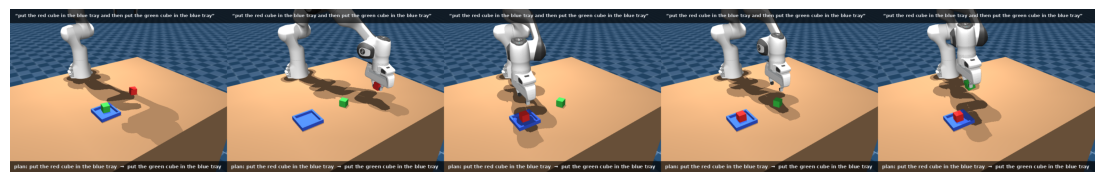

In [5]:
# show an episode whose System-2 plan was correct (fall back to the oracle plan if none was)
ok_idx = [i for i, (p, (_, tr)) in enumerate(zip(plans, episodes)) if [s["instruction"] for s in p] == [s["instruction"] for s in tr]]
full = [i for i in ok_idx if results["dual: LM plan -> System 1"][i] == 1.0]   # prefer an episode where both steps succeeded
ok_idx = full + [i for i in ok_idx if i not in full]
i = ok_idx[0] if ok_idx else 0
plan_i = plans[i] if ok_idx else episodes[i][1]
env.start_video("showcase", (480, 640))                    # HD recording of the whole multi-step episode
done = run_episode(env, sys1, plan_i, 90_000 + i)
from vlacourse import showcase as sc
hd = [sc.caption(f, f"“{episodes[i][0]}”", where="top") for f in env.stop_video()]
hd = [sc.caption(f, "plan: " + "  →  ".join(st["instruction"] for st in plan_i), size=16) for f in hd]
print(f"task: {episodes[i][0]} | plan from {'System 2' if ok_idx else 'the oracle'} | sub-tasks completed: {done}/2")
show_video(hd, fps=30, title="115 dual-system agent (HD)")
plt.figure(figsize=(14, 2.6)); plt.imshow(np.hstack(hd[::max(1, len(hd) // 5)][:5])); plt.axis("off"); plt.show()